In [67]:
from dataloader import load_all_data
import pandas as pd
import numpy as np
import scipy
from scipy import stats
import tqdm

import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
plt.rcParams['text.usetex'] = True
plt.rcParams['text.latex.preamble'] = r'''\usepackage{libertine}\usepackage{fontawesome5}\usepackage{xcolor}'''
plt.rcParams['ps.usedistiller'] = 'xpdf'
import seaborn as sns
sns.set_theme(style='ticks')
from statannotations.Annotator import Annotator

In [2]:
colors = ['#c26f6d', '#d9a6a4', '#f2dfdd', '#e4e5eb', '#aab8d0', '#6e90bf']
interfaces = {
    'pointwise':        'UI1',
    'pairwise':         'UI2',
    'listwise-rating':  'UI3',
    'listwise-notie':   'UI4',
    'listwise-cantie':  'UI5',
    'listwise-ranking': 'UI6',
}

df_begins, df_all, df_finishs, df_demographic = load_all_data()

pointwise
pairwise
listwise-rating
listwise-notie
listwise-cantie
listwise-ranking
pointwise
pairwise
listwise-rating
listwise-notie
listwise-cantie
listwise-ranking


In [3]:
df_progress = df_all[['userID', 'domain', 'taskID', 'interface', 'iteration', 'rating', 'skip', 'parameters', 'options']]
df_progress

,userID,domain,taskID,interface,iteration,rating,skip,parameters,options
0,P330,text,3,pointwise,1,83,False,"[{'reduction_ratio': 0.1924789845943451, 'top_...",[text/1/pointwise/P330-630...
1,P330,text,3,pointwise,2,87,False,"[{'reduction_ratio': 0.7346476912498474, 'top_...",[text/1/pointwise/P330-630...
2,P330,text,3,pointwise,3,71,False,"[{'reduction_ratio': 0.9412690997123718, 'top_...",[text/1/pointwise/P330-630...
3,P330,text,3,pointwise,4,81,False,"[{'reduction_ratio': 0.5664541125297546, 'top_...",[text/1/pointwise/P330-630...
4,P330,text,3,pointwise,5,81,False,"[{'reduction_ratio': 0.34385254979133606, 'top...",[text/1/pointwise/P330-630...
...,...,...,...,...,...,...,...,...,...
8930,P149,image,2,listwise-ranking,2,"[{'id': 0, 'rating': 'Excellent', 'timestamp':...",False,"[{'brightness': 0.571182370185852, 'contrast':...",[image/1/listwise-ranking/60b63cc430b27a19351d...
8931,P149,image,2,listwise-ranking,3,"[{'id': 1, 'rating': 'Fair', 'timestamp': 1670...",False,"[{'brightness': 0.629599392414093, 'contrast':...",[image/1/listwise-ranking/60b63cc430b27a19351d...
8932,P149,image,2,listwise-ranking,4,"[{'id': 0, 'rating': 'I don't know', 'timestam...",False,"[{'brightness': 0.4798765480518341, 'contrast'...",[image/1/listwise-ranking/60b63cc430b27a19351d...
8933,P149,image,2,listwise-ranking,5,"[{'id': 2, 'rating': 'Excellent', 'timestamp':...",False,"[{'brightness': 0.2839641869068146, 'contrast'...",[image/1/listwise-ranking/60b63cc430b27a19351d...


In [4]:
import torch
from botorch.models.pairwise_gp import PairwiseGP, PairwiseLaplaceMarginalLogLikelihood
from botorch.acquisition.preference import AnalyticExpectedUtilityOfBestOption
from botorch.acquisition import qExpectedImprovement, UpperConfidenceBound
from botorch.fit import fit_gpytorch_model
from botorch.optim import optimize_acqf
from gpytorch.kernels.matern_kernel import MaternKernel
from gpytorch.kernels.scale_kernel import ScaleKernel
from gpytorch.priors.torch_priors import GammaPrior

torch.manual_seed(42) # for reproducibility

def eubo(X: torch.tensor, y: torch.tensor, dim: int):
    bounds = torch.stack([torch.zeros(dim), torch.ones(dim)])
    gp = PairwiseGP(X, y,
                    covar_module=ScaleKernel(
                        MaternKernel(nu=2.5,
                            lengthscale_prior=GammaPrior(3.0, 6.0),
                        ),
                        outputscale_prior=GammaPrior(2.0, 0.15),
                    ))
    mll = PairwiseLaplaceMarginalLogLikelihood(gp.likelihood, gp)
    fit_gpytorch_model(mll)

    candidates, acq_val = optimize_acqf(
        acq_function=AnalyticExpectedUtilityOfBestOption(pref_model=gp),
        bounds=bounds,
        q=2,
        num_restarts=5,
        raw_samples=20,
    )
    return candidates, acq_val, gp

# UI2: Pairwise Latent Utility


In [6]:
df_pairwise_latent = df_all[['userID', 'domain', 'taskID', 'interface', 'iteration', 'parameters', 'rating']]
df_pairwise_latent = df_pairwise_latent[(df_pairwise_latent.interface == 'pairwise')]

,userID,domain,taskID,interface,iteration,parameters,rating
715,P161,text,2,pairwise,1,"[{'reduction_ratio': 0.8997868895530701, 'top_...",2
716,P161,text,2,pairwise,2,"[{'reduction_ratio': 0.19033755362033844, 'top...",2
717,P161,text,2,pairwise,3,"[{'reduction_ratio': 0.6575882434844971, 'top_...",3
718,P161,text,2,pairwise,4,"[{'reduction_ratio': 0.5762887001037598, 'top_...",3
719,P161,text,2,pairwise,5,"[{'reduction_ratio': 0.013404804281890392, 'to...",3
...,...,...,...,...,...,...,...
5775,P248,image,3,pairwise,3,"[{'brightness': 0.49613821506500244, 'contrast...",1
5776,P248,image,3,pairwise,4,"[{'brightness': 0.5807035565376282, 'contrast'...",2
5777,P248,image,3,pairwise,5,"[{'brightness': 0.9714512228965759, 'contrast'...",1
5778,P248,image,3,pairwise,6,"[{'brightness': 0.9429992437362671, 'contrast'...",2


In [12]:
df_pairwise_latent_progress = pd.DataFrame()
# For each user, for each task
for user in tqdm.tqdm(df_pairwise_latent.userID.unique()):
    df_user_progress = pd.DataFrame()
    df_user = df_pairwise_latent[df_pairwise_latent.userID == user]
    for task in df_user.taskID.unique():
        acqvals = []
        gpranks = []

        # In each task, for each iteration
        df_task = df_user[df_user.taskID == task].reset_index(drop=True)
        for idx, row in df_task.iterrows():
            # For each iteration, accumulate historical parameters and selections
            X, y, i = [], [], 0
            for idx, perrow in df_task[df_task.iteration <= row.iteration].iterrows():
                param1 = perrow.parameters[0] # left
                param2 = perrow.parameters[1] # right

                if perrow.domain == 'text':
                    X.append([param1['reduction_ratio'], param1['top_p'], param1['temperature'], param1['length_penalty']])
                    X.append([param2['reduction_ratio'], param2['top_p'], param2['temperature'], param2['length_penalty']])
                elif perrow.domain == 'image':
                    X.append([param1['brightness'], param1['contrast'], param1['saturation'], param1['temperature'], param1['tint']])
                    X.append([param2['brightness'], param2['contrast'], param2['saturation'], param2['temperature'], param2['tint']])
                if perrow.rating == 1:   # left is better
                    y.append([i, i+1])
                elif perrow.rating == 2: # right is better
                    y.append([i+1, i])
                else:
                    y.append([i, i+1])
                    y.append([i+1, i])
                i += 2

            # Then train the utility function based on the historical data.
            X = torch.tensor(X, dtype=torch.float32)
            y = torch.tensor(y, dtype=torch.float32)
            candidates, acq_val, gp = eubo(X, y, X.shape[1])
            acqvals.append(acq_val.detach().numpy())
            gpranks.append(gp.utility.max().detach().numpy())

        l = scipy.signal.resample(acqvals, 20)
        lgprank = scipy.signal.resample(gpranks, 20)
        for i, v in enumerate(l):
            df_user_progress = df_user_progress.append({
                'userID': user,
                'domain': df_task.domain[0],
                'taskID': task,
                'iteration': i,
                'utility': v,
                'gprank': lgprank[i],
            }, ignore_index=True)

    # normalize utility from 0 to 1 (normalize per user)
    df_user_progress['utility'] = (df_user_progress.utility - df_user_progress.utility.min()) / (df_user_progress.utility.max() - df_user_progress.utility.min())
    df_pairwise_latent_progress = df_pairwise_latent_progress.append(df_user_progress, ignore_index=True)

df_pairwise_latent_progress.to_csv('processed/pairwise_latent_progress.csv', index=False)
df_pairwise_latent_progress

100%|██████████| 60/60 [05:29<00:00,  5.48s/it]


# UI4: Listwise No tie Utility


In [20]:
import random

df_listwise_notie_latent = df_all[['userID', 'domain', 'taskID', 'interface', 'iteration', 'parameters', 'rating']]
df_listwise_notie_latent = df_listwise_notie_latent[(df_listwise_notie_latent.interface == 'listwise-notie')]
df_listwise_notie_latent

users = df_listwise_notie_latent.userID.unique()
df_listwise_notie_latent_progress = pd.DataFrame()
for user in tqdm.tqdm(users):
    df_user_progress = pd.DataFrame()
    df_user = df_listwise_notie_latent[df_listwise_notie_latent.userID == user]

    for task in df_user.taskID.unique():
        acqvals = []
        gpranks = []
        # Train pairwise ranking utility per task.
        df_task = df_user[df_user.taskID == task].reset_index(drop=True)
        for idx, row in df_task.iterrows():
            # For each iteration, accumulate historical parameters and selections
            X, y, k = [], [], 0
            for idx, perrow in df_task[df_task.iteration <= row.iteration].iterrows():
                param1 = perrow.parameters[0]
                param2 = perrow.parameters[1]
                param3 = perrow.parameters[2]
                param4 = perrow.parameters[3]
                params = []
                if perrow.domain == 'text':
                    params.append([param1['reduction_ratio'], param1['top_p'], param1['temperature'], param1['length_penalty']])
                    params.append([param2['reduction_ratio'], param2['top_p'], param2['temperature'], param2['length_penalty']])
                    params.append([param3['reduction_ratio'], param3['top_p'], param3['temperature'], param3['length_penalty']])
                    params.append([param4['reduction_ratio'], param4['top_p'], param4['temperature'], param4['length_penalty']])
                elif perrow.domain == 'image':
                    params.append([param1['brightness'], param1['contrast'], param1['saturation'], param1['temperature'], param1['tint']])
                    params.append([param2['brightness'], param2['contrast'], param2['saturation'], param2['temperature'], param2['tint']])
                    params.append([param3['brightness'], param3['contrast'], param3['saturation'], param3['temperature'], param3['tint']])
                    params.append([param4['brightness'], param4['contrast'], param4['saturation'], param4['temperature'], param4['tint']])

                # infer ranking orders
                ranking = [-1, -1, -1, -1]
                for op in perrow.rating:
                    if op['rating'] == '1st Choice':
                        ranking[0] = op['id']
                    elif op['rating'] == '2nd Choice':
                        ranking[1] = op['id']
                    elif op['rating'] == '3rd Choice':
                        ranking[2] = op['id']
                    elif op['rating'] == '4th Choice':
                        ranking[3] = op['id']
                    else:  # I don't know, incomplete preference, we don't use these data for training
                        pass

                comparisons = []
                if ranking[0] != -1 and ranking[1] != -1:
                    comparisons.append([ranking[0]+k, ranking[1]+k])
                elif ranking[0] != -1 and ranking[2] != -1:
                    comparisons.append([ranking[0]+k, ranking[2]+k])
                elif ranking[0] != -1 and ranking[3] != -1:
                    comparisons.append([ranking[0]+k, ranking[3]+k])
                elif ranking[1] != -1 and ranking[2] != -1:
                    comparisons.append([ranking[1]+k, ranking[2]+k])
                elif ranking[1] != -1 and ranking[3] != -1:
                    comparisons.append([ranking[1]+k, ranking[3]+k])
                elif ranking[2] != -1 and ranking[3] != -1:
                    comparisons.append([ranking[2]+k, ranking[3]+k])
                else:
                    comparisons.append([random.randint(0, len(params)-1), random.randint(0, len(params)-1)])

                X += params
                y += comparisons
                k += 4

            # Then train the utility function based on the historical data.
            # Estimate the next best parameters using all the historical data.
            X = torch.tensor(X)
            y = torch.tensor(y)

            candidates, acq_val, gp = eubo(X, y, X.shape[1])
            acqvals.append(acq_val.detach().numpy())
            gpranks.append(gp.utility.mean().detach().numpy())

        l = scipy.signal.resample(acqvals, 20)
        lgprank = scipy.signal.resample(gpranks, 20)
        for i, v in enumerate(l):
            df_user_progress = df_user_progress.append({
                'userID': user,
                'domain': df_task.domain[0],
                'taskID': task,
                'iteration': i,
                'utility': v,
                'gprank': lgprank[i],
            }, ignore_index=True)

    # normalize utility from 0 to 1 (normalize per user)
    df_user_progress['utility'] = (df_user_progress.utility - df_user_progress.utility.min()) / (df_user_progress.utility.max() - df_user_progress.utility.min())
    df_listwise_notie_latent_progress = df_listwise_notie_latent_progress.append(df_user_progress, ignore_index=True)

df_listwise_notie_latent_progress.to_csv('processed/listwise_notie_latent_progress.csv', index=False)
df_listwise_notie_latent_progress

  0%|          | 0/60 [00:00<?, ?it/s]

[{'id': 1, 'rating': '1st Choice', 'timestamp': 1661926319504}, {'id': 2, 'rating': '2nd Choice', 'timestamp': 1661926321452}, {'id': 3, 'rating': '3rd Choice', 'timestamp': 1661926322703}, {'id': 0, 'rating': '4th Choice', 'timestamp': 1661926323965}]
P041 text 3 19
torch.Size([4, 4]) torch.Size([1, 2])
[{'id': 1, 'rating': '1st Choice', 'timestamp': 1661926319504}, {'id': 2, 'rating': '2nd Choice', 'timestamp': 1661926321452}, {'id': 3, 'rating': '3rd Choice', 'timestamp': 1661926322703}, {'id': 0, 'rating': '4th Choice', 'timestamp': 1661926323965}]
[{'id': 2, 'rating': '1st Choice', 'timestamp': 1661926538729}, {'id': 3, 'rating': '2nd Choice', 'timestamp': 1661926552758}, {'id': 0, 'rating': '3rd Choice', 'timestamp': 1661926554692}, {'id': 1, 'rating': '4th Choice', 'timestamp': 1661926555956}, {'id': 3, 'rating': '3rd Choice', 'timestamp': 1661926557439}, {'id': 0, 'rating': '2nd Choice', 'timestamp': 1661926557439}, {'id': 0, 'rating': '3rd Choice', 'timestamp': 1661926559676},

  2%|▏         | 1/60 [00:03<03:55,  4.00s/it]

[{'id': 3, 'rating': '1st Choice', 'timestamp': 1661926297603}, {'id': 2, 'rating': '2nd Choice', 'timestamp': 1661926300819}, {'id': 0, 'rating': '3rd Choice', 'timestamp': 1661926314785}, {'id': 1, 'rating': '4th Choice', 'timestamp': 1661926317288}]
P116 text 2 19
torch.Size([4, 4]) torch.Size([1, 2])
[{'id': 3, 'rating': '1st Choice', 'timestamp': 1661926297603}, {'id': 2, 'rating': '2nd Choice', 'timestamp': 1661926300819}, {'id': 0, 'rating': '3rd Choice', 'timestamp': 1661926314785}, {'id': 1, 'rating': '4th Choice', 'timestamp': 1661926317288}]
[{'id': 0, 'rating': '4th Choice', 'timestamp': 1661926490935}, {'id': 3, 'rating': '1st Choice', 'timestamp': 1661926494355}, {'id': 2, 'rating': '2nd Choice', 'timestamp': 1661926496152}, {'id': 1, 'rating': '3rd Choice', 'timestamp': 1661926498270}]
P116 text 2 19
torch.Size([8, 4]) torch.Size([2, 2])
[{'id': 3, 'rating': '1st Choice', 'timestamp': 1661926297603}, {'id': 2, 'rating': '2nd Choice', 'timestamp': 1661926300819}, {'id': 0

  3%|▎         | 2/60 [00:07<03:22,  3.49s/it]

...

[{'id': 3, 'rating': '1st Choice', 'timestamp': 1670171260189}, {'id': 1, 'rating': '2nd Choice', 'timestamp': 1670171264974}, {'id': 2, 'rating': '3rd Choice', 'timestamp': 1670171268343}, {'id': 0, 'rating': '4th Choice', 'timestamp': 1670171269776}]
P160 image 2 19
torch.Size([4, 5]) torch.Size([1, 2])
[{'id': 3, 'rating': '1st Choice', 'timestamp': 1670171260189}, {'id': 1, 'rating': '2nd Choice', 'timestamp': 1670171264974}, {'id': 2, 'rating': '3rd Choice', 'timestamp': 1670171268343}, {'id': 0, 'rating': '4th Choice', 'timestamp': 1670171269776}]
[{'id': 1, 'rating': '1st Choice', 'timestamp': 1670171315676}, {'id': 3, 'rating': '2nd Choice', 'timestamp': 1670171331732}, {'id': 2, 'rating': '3rd Choice', 'timestamp': 1670171334765}, {'id': 0, 'rating': '4th Choice', 'timestamp': 1670171336465}]
P160 image 2 19
torch.Size([8, 5]) torch.Size([2, 2])
[{'id': 3, 'rating': '1st Choice', 'timestamp': 1670171260189}, {'id': 1, 'rating': '2nd Choice', 'timestamp': 1670171264974}, {'id':

 98%|█████████▊| 59/60 [04:40<00:06,  6.15s/it]

[{'id': 0, 'rating': '2nd Choice', 'timestamp': 1670172140540}, {'id': 1, 'rating': '1st Choice', 'timestamp': 1670172141755}, {'id': 2, 'rating': '3rd Choice', 'timestamp': 1670172146682}, {'id': 3, 'rating': '4th Choice', 'timestamp': 1670172148429}]
[{'id': 0, 'rating': '1st Choice', 'timestamp': 1670172371092}, {'id': 1, 'rating': '4th Choice', 'timestamp': 1670172375392}, {'id': 2, 'rating': '2nd Choice', 'timestamp': 1670172379616}, {'id': 3, 'rating': '3rd Choice', 'timestamp': 1670172381987}]
P117 image 1 19
torch.Size([8, 5]) torch.Size([2, 2])
[{'id': 0, 'rating': '2nd Choice', 'timestamp': 1670172140540}, {'id': 1, 'rating': '1st Choice', 'timestamp': 1670172141755}, {'id': 2, 'rating': '3rd Choice', 'timestamp': 1670172146682}, {'id': 3, 'rating': '4th Choice', 'timestamp': 1670172148429}]
[{'id': 3, 'rating': '1st Choice', 'timestamp': 1670172194176}, {'id': 2, 'rating': '3rd Choice', 'timestamp': 1670172196902}, {'id': 1, 'rating': '2nd Choice', 'timestamp': 1670172198580

100%|██████████| 60/60 [04:45<00:00,  4.75s/it]


,userID,domain,taskID,iteration,utility,gprank
0,P041,text,3,0,0.113453,-0.044772
1,P041,text,3,1,0.168818,-0.021080
2,P041,text,3,2,0.268862,0.002844
3,P041,text,3,3,0.364938,0.019474
4,P041,text,3,4,0.417296,0.024794
...,...,...,...,...,...,...
3595,P117,image,3,15,1.000000,-0.031611
3596,P117,image,3,16,0.954001,-0.027300
3597,P117,image,3,17,0.770242,-0.029760
3598,P117,image,3,18,0.481659,-0.042748


# UI5: Listwise Can Tie Utility


In [30]:
df_listwise_cantie_latent = df_all[['userID', 'domain', 'taskID', 'interface', 'iteration', 'parameters', 'rating']]
df_listwise_cantie_latent = df_listwise_cantie_latent[(df_listwise_cantie_latent.interface == 'listwise-cantie')]
df_listwise_cantie_latent

users = df_listwise_cantie_latent.userID.unique()
df_listwise_cantie_latent_progress = pd.DataFrame()
for user in tqdm.tqdm(users):
    df_user_progress = pd.DataFrame()
    df_user = df_listwise_cantie_latent[df_listwise_cantie_latent.userID == user]

    for task in df_user.taskID.unique():
        acqvals = []
        gpranks = []
        # Train pairwise ranking utility per task.
        df_task = df_user[df_user.taskID == task].reset_index(drop=True)
        for idx, row in df_task.iterrows():
            # For each iteration, accumulate historical parameters and selections
            X, y, k = [], [], 0
            for idx, perrow in df_task[df_task.iteration <= row.iteration].iterrows():
                params = []
                param1 = perrow.parameters[0]
                param2 = perrow.parameters[1]
                param3 = perrow.parameters[2]
                param4 = perrow.parameters[3]
                if perrow.domain == 'text':
                    params.append([param1['reduction_ratio'], param1['top_p'], param1['temperature'], param1['length_penalty']])
                    params.append([param2['reduction_ratio'], param2['top_p'], param2['temperature'], param2['length_penalty']])
                    params.append([param3['reduction_ratio'], param3['top_p'], param3['temperature'], param3['length_penalty']])
                    params.append([param4['reduction_ratio'], param4['top_p'], param4['temperature'], param4['length_penalty']])
                elif perrow.domain == 'image':
                    params.append([param1['brightness'], param1['contrast'], param1['saturation'], param1['temperature'], param1['tint']])
                    params.append([param2['brightness'], param2['contrast'], param2['saturation'], param2['temperature'], param2['tint']])
                    params.append([param3['brightness'], param3['contrast'], param3['saturation'], param3['temperature'], param3['tint']])
                    params.append([param4['brightness'], param4['contrast'], param4['saturation'], param4['temperature'], param4['tint']])

                # infer rating position
                rating = ['', '', '', '']
                for op in perrow.rating:
                    rating[op['id']] = op['rating']
                rating_map = {
                    '1st Choice': 5,
                    '2nd Choice': 4,
                    '3rd Choice': 3,
                    '4th Choice': 2,
                    "I don't know": -1,
                }
                # convert rating to pairwise comparisons.
                ranking = [rating_map[r] for r in rating]

                comparisons = []
                if ranking[0] != -1 and ranking[1] != -1:
                    if ranking[0] > ranking[1]:
                        comparisons.append([0+k, 1+k])
                    elif ranking[0] < ranking[1]:
                        comparisons.append([1+k, 0+k])
                    else:
                        # Handling ties.
                        comparisons.append([0+k, 1+k])
                        # comparisons.append([1+k, 0+k])
                elif ranking[0] != -1 and ranking[2] != -1:
                    if ranking[0] > ranking[2]:
                        comparisons.append([0+k, 2+k])
                    elif ranking[0] < ranking[2]:
                        comparisons.append([2+k, 0+k])
                    else:
                        # Handling ties.
                        comparisons.append([0+k, 2+k])
                        # comparisons.append([2+k, 0+k])
                elif ranking[0] != -1 and ranking[3] != -1:
                    if ranking[0] > ranking[3]:
                        comparisons.append([0+k, 3+k])
                    elif ranking[0] < ranking[3]:
                        comparisons.append([3+k, 0+k])
                    else:
                        # Handling ties.
                        comparisons.append([0+k, 3+k])
                        # comparisons.append([3+k, 0+k])
                elif ranking[1] != -1 and ranking[2] != -1:
                    if ranking[1] > ranking[2]:
                        comparisons.append([1+k, 2+k])
                    elif ranking[1] < ranking[2]:
                        comparisons.append([2+k, 1+k])
                    else:
                        # Handling ties.
                        comparisons.append([1+k, 2+k])
                        # comparisons.append([2+k, 1+k])
                elif ranking[1] != -1 and ranking[3] != -1:
                    if ranking[1] > ranking[3]:
                        comparisons.append([1+k, 3+k])
                    elif ranking[1] < ranking[3]:
                        comparisons.append([3+k, 1+k])
                    else:
                        # Handling ties.
                        comparisons.append([1+k, 3+k])
                        # comparisons.append([3+k, 1+k])
                elif ranking[2] != -1 and ranking[3] != -1:
                    if ranking[2] > ranking[3]:
                        comparisons.append([2+k, 3+k])
                    elif ranking[2] < ranking[3]:
                        comparisons.append([3+k, 2+k])
                    else:
                        # Handling ties.
                        comparisons.append([2+k, 3+k])
                        # comparisons.append([3+k, 2+k])
                else:
                    comparisons.append([random.randint(0, len(params)-1), random.randint(0, len(params)-1)])

                X += params
                y += comparisons
                k += 4

            # Then train the utility function based on the historical data.
            X = torch.tensor(X)
            y = torch.tensor(y)

            candidates, acq_val, gp = eubo(X, y, X.shape[1])
            acqvals.append(acq_val.detach().numpy())
            gpranks.append(gp.utility.max().detach().numpy())

        l = scipy.signal.resample(acqvals, 20)
        lgprank = scipy.signal.resample(gpranks, 20)
        for i, v in enumerate(l):
            df_user_progress = df_user_progress.append({
                'userID': user,
                'domain': df_task.domain[0],
                'taskID': task,
                'iteration': i,
                'utility': v,
                'gprank': lgprank[i],
            }, ignore_index=True)

    # normalize utility from 0 to 1 (normalize per user)
    df_user_progress['utility'] = (df_user_progress.utility - df_user_progress.utility.min()) / (df_user_progress.utility.max() - df_user_progress.utility.min())
    df_listwise_cantie_latent_progress = df_listwise_cantie_latent_progress.append(df_user_progress, ignore_index=True)

df_listwise_cantie_latent_progress.to_csv('processed/listwise_cantie_latent_progress.csv', index=False)

100%|██████████| 60/60 [04:49<00:00,  4.83s/it]


# UI6: Listwise Ranking Latent Utility


In [40]:
df_listwise_ranking_latent = df_all[['userID', 'domain', 'taskID', 'interface', 'iteration', 'parameters', 'rating', 'skip']]
df_listwise_ranking_latent = df_listwise_ranking_latent[(df_listwise_ranking_latent.interface == 'listwise-ranking')]
df_listwise_ranking_latent

users = df_listwise_ranking_latent.userID.unique()
df_listwise_ranking_latent_progress = pd.DataFrame()
for user in tqdm.tqdm(users):
    df_user_progress = pd.DataFrame()
    df_user = df_listwise_ranking_latent[df_listwise_ranking_latent.userID == user]

    for task in df_user.taskID.unique():
        acqvals = []
        gpranks = []
        # Train pairwise ranking utility per task.
        df_task = df_user[df_user.taskID == task].reset_index(drop=True)
        for idx, row in df_task.iterrows():
            X, y, k = [], [], 0
            for idx, perrow in df_task[df_task.iteration <= row.iteration].iterrows():
                params = []
                param1 = perrow.parameters[0]
                param2 = perrow.parameters[1]
                param3 = perrow.parameters[2]
                param4 = perrow.parameters[3]
                if perrow.domain == 'text':
                    params.append([param1['reduction_ratio'], param1['top_p'], param1['temperature'], param1['length_penalty']])
                    params.append([param2['reduction_ratio'], param2['top_p'], param2['temperature'], param2['length_penalty']])
                    params.append([param3['reduction_ratio'], param3['top_p'], param3['temperature'], param3['length_penalty']])
                    params.append([param4['reduction_ratio'], param4['top_p'], param4['temperature'], param4['length_penalty']])
                elif perrow.domain == 'image':
                    params.append([param1['brightness'], param1['contrast'], param1['saturation'], param1['temperature'], param1['tint']])
                    params.append([param2['brightness'], param2['contrast'], param2['saturation'], param2['temperature'], param2['tint']])
                    params.append([param3['brightness'], param3['contrast'], param3['saturation'], param3['temperature'], param3['tint']])
                    params.append([param4['brightness'], param4['contrast'], param4['saturation'], param4['temperature'], param4['tint']])

                # infer rating position
                rating = ['', '', '', '']
                for op in perrow.rating:
                    rating[op['id']] = op['rating']
                rating_map = {
                    'Excellent': 5,
                    'Good': 4,
                    'Fair': 3,
                    'Poor': 2,
                    'Terrible': 1,
                    "I don't know": -1,
                }
                ranking = [rating_map[r] for r in rating]

                comparisons = []
                if ranking[0] != -1 and ranking[1] != -1:
                    if ranking[0] > ranking[1]:
                        comparisons.append([0+k, 1+k])
                    elif ranking[0] < ranking[1]:
                        comparisons.append([1+k, 0+k])
                    else:
                        # Handling ties.
                        comparisons.append([0+k, 1+k])
                        # comparisons.append([1+k, 0+k])
                elif ranking[0] != -1 and ranking[2] != -1:
                    if ranking[0] > ranking[2]:
                        comparisons.append([0+k, 2+k])
                    elif ranking[0] < ranking[2]:
                        comparisons.append([2+k, 0+k])
                    else:
                        # Handling ties.
                        comparisons.append([0+k, 2+k])
                        # comparisons.append([2+k, 0+k])
                elif ranking[0] != -1 and ranking[3] != -1:
                    if ranking[0] > ranking[3]:
                        comparisons.append([0+k, 3+k])
                    elif ranking[0] < ranking[3]:
                        comparisons.append([3+k, 0+k])
                    else:
                        # Handling ties.
                        comparisons.append([0+k, 3+k])
                        # comparisons.append([3+k, 0+k])
                elif ranking[1] != -1 and ranking[2] != -1:
                    if ranking[1] > ranking[2]:
                        comparisons.append([1+k, 2+k])
                    elif ranking[1] < ranking[2]:
                        comparisons.append([2+k, 1+k])
                    else:
                        # Handling ties.
                        comparisons.append([1+k, 2+k])
                        # comparisons.append([2+k, 1+k])
                elif ranking[1] != -1 and ranking[3] != -1:
                    if ranking[1] > ranking[3]:
                        comparisons.append([1+k, 3+k])
                    elif ranking[1] < ranking[3]:
                        comparisons.append([3+k, 1+k])
                    else:
                        # Handling ties.
                        comparisons.append([1+k, 3+k])
                        # comparisons.append([3+k, 1+k])
                elif ranking[2] != -1 and ranking[3] != -1:
                    if ranking[2] > ranking[3]:
                        comparisons.append([2+k, 3+k])
                    elif ranking[2] < ranking[3]:
                        comparisons.append([3+k, 2+k])
                    else:
                        # Handling ties.
                        comparisons.append([2+k, 3+k])
                        # comparisons.append([3+k, 2+k])

                X += params
                y += comparisons
                k += 4

            # Then train the utility function based on the historical data.
            X = torch.tensor(X)
            y = torch.tensor(y)

            candidates, acq_val, gp = eubo(X, y, X.shape[1])
            acqvals.append(acq_val.detach().numpy())
            gpranks.append(gp.utility.max().detach().numpy())

        l = scipy.signal.resample(acqvals, 20)
        lgprank = scipy.signal.resample(gpranks, 20)
        for i, v in enumerate(l):
            df_user_progress = df_user_progress.append({
                'userID': user,
                'domain': df_task.domain[0],
                'taskID': task,
                'iteration': i,
                'utility': v,
                'gprank': lgprank[i],
            }, ignore_index=True)

    # normalize utility from 0 to 1 (normalize per user)
    df_user_progress['utility'] = (df_user_progress.utility - df_user_progress.utility.min()) / (df_user_progress.utility.max() - df_user_progress.utility.min())
    df_listwise_ranking_latent_progress = df_listwise_ranking_latent_progress.append(df_user_progress, ignore_index=True)

df_listwise_ranking_latent_progress.to_csv('processed/listwise_ranking_latent_progress.csv', index=False)

100%|██████████| 60/60 [04:44<00:00,  4.74s/it]


In [ ]:
import pandas as pd

df_pairwise_latent_progress = pd.read_csv('processed/pairwise_latent_progress.csv')
df_listwise_notie_latent_progress = pd.read_csv('processed/listwise_notie_latent_progress.csv')
df_listwise_cantie_latent_progress = pd.read_csv('processed/listwise_cantie_latent_progress.csv')
df_listwise_ranking_latent_progress = pd.read_csv('processed/listwise_ranking_latent_progress.csv')

df_pairwise_latent_progress['interface'] = 'pairwise'
df_listwise_notie_latent_progress['interface'] = 'listwise-notie'
df_listwise_cantie_latent_progress['interface'] = 'listwise-cantie'
df_listwise_ranking_latent_progress['interface'] = 'listwise-ranking'

df = pd.concat([df_pairwise_latent_progress, df_listwise_notie_latent_progress, df_listwise_cantie_latent_progress, df_listwise_ranking_latent_progress], ignore_index=True)

df.to_csv('processed/latent_utility.csv', index=False)

## Visualize UI2, UI4, UI5 and UI6 Utility (Latent Utility)


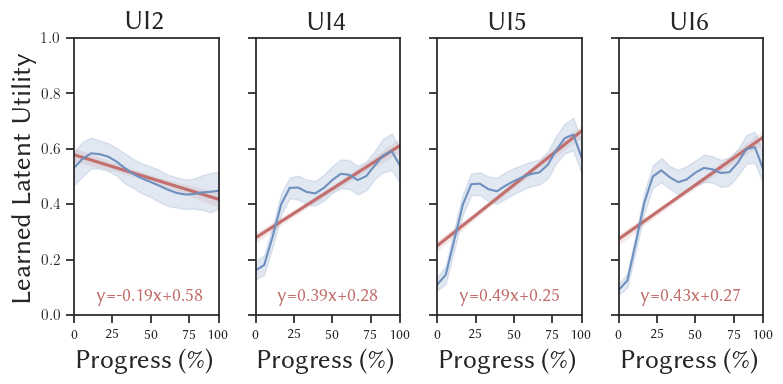

In [76]:
df_pairwise_latent_progress = pd.read_csv('processed/pairwise_latent_progress.csv')
df_listwise_notie_latent_progress = pd.read_csv('processed/listwise_notie_latent_progress.csv')
df_listwise_cantie_latent_progress = pd.read_csv('processed/listwise_cantie_latent_progress.csv')
df_listwise_ranking_latent_progress = pd.read_csv('processed/listwise_ranking_latent_progress.csv')

def draw_latent_utility_progress(domain):
    maxiter = 18
    df_pairwise_latent_progress_domain = df_pairwise_latent_progress[(df_pairwise_latent_progress.domain == domain) & (df_pairwise_latent_progress.iteration < maxiter)]
    df_listwise_notie_latent_progress_domain = df_listwise_notie_latent_progress[(df_listwise_notie_latent_progress.domain == domain) & (df_listwise_notie_latent_progress.iteration < maxiter)]
    df_listwise_cantie_latent_progress_domain = df_listwise_cantie_latent_progress[(df_listwise_cantie_latent_progress.domain == domain) & (df_listwise_cantie_latent_progress.iteration < maxiter)]
    df_listwise_ranking_latent_progress_domain = df_listwise_ranking_latent_progress[(df_listwise_ranking_latent_progress.domain == domain) & (df_listwise_ranking_latent_progress.iteration < maxiter)]

    slope, intercept, r_value, p_value, std_err = stats.linregress(df_pairwise_latent_progress_domain['iteration'], df_pairwise_latent_progress_domain['utility'])
    fig, axes = plt.subplots(1, 4, figsize=(8, 4))
    sns.regplot(ax=axes[0], data=df_pairwise_latent_progress_domain, x='iteration', y='utility', scatter=False, color=colors[0], order=1)
    sns.lineplot(ax=axes[0], data=df_pairwise_latent_progress_domain, x='iteration', y='utility', color=colors[-1])
    axes[0].set_xticks([0, maxiter*1/4, maxiter*2/4, maxiter*3/4, maxiter-1])
    axes[0].set_xlim(0, maxiter-1)
    axes[0].set_xticklabels([0, int(500/20), int(1000/20), int(1500/20), 100])
    axes[0].set_ylabel('Learned Latent Utility', fontsize=20)
    axes[0].annotate('y={:.2f}x+{:.2f}'.format(slope*20, intercept), xy=(0.15, 0.05), xycoords='axes fraction', fontsize=14, color=colors[0])
    axes[0].set_xlabel('Progress (\%)', fontsize=20)
    axes[0].set_title('UI2', fontsize=20)
    axes[0].set_ylim(0, 1)

    slope, intercept, r_value, p_value, std_err = stats.linregress(df_listwise_notie_latent_progress_domain['iteration'], df_listwise_notie_latent_progress_domain['utility'])
    sns.regplot(ax=axes[1], data=df_listwise_notie_latent_progress_domain, x='iteration', y='utility', scatter=False, color=colors[0], order=1)
    sns.lineplot(ax=axes[1], data=df_listwise_notie_latent_progress_domain, x='iteration', y='utility', color=colors[-1])
    axes[1].set_xticks([0, maxiter*1/4, maxiter*2/4, maxiter*3/4, maxiter-1])
    axes[1].set_xlim(0, maxiter-1)
    axes[1].set_xticklabels([0, int(500/20), int(1000/20), int(1500/20), 100])
    axes[1].set_ylabel('', fontsize=20)
    axes[1].annotate('y={:.2f}x+{:.2f}'.format(slope*20, intercept), xy=(0.15, 0.05), xycoords='axes fraction', fontsize=14, color=colors[0])
    axes[1].set_xlabel('Progress (\%)', fontsize=20)
    axes[1].set_title('UI4', fontsize=20)
    axes[1].set_yticklabels([])
    axes[1].set_ylim(0, 1)

    slope, intercept, r_value, p_value, std_err = stats.linregress(df_listwise_cantie_latent_progress_domain['iteration'], df_listwise_cantie_latent_progress_domain['utility'])
    sns.regplot(ax=axes[2], data=df_listwise_cantie_latent_progress_domain, x='iteration', y='utility', scatter=False, color=colors[0], order=1)
    sns.lineplot(ax=axes[2], data=df_listwise_cantie_latent_progress_domain, x='iteration', y='utility', color=colors[-1])
    axes[2].set_xticks([0, maxiter*1/4, maxiter*2/4, maxiter*3/4, maxiter-1])
    axes[2].set_xlim(0, maxiter-1)
    axes[2].set_xticklabels([0, int(500/20), int(1000/20), int(1500/20), 100])
    axes[2].set_ylabel('', fontsize=20)
    axes[2].annotate('y={:.2f}x+{:.2f}'.format(slope*20, intercept), xy=(0.15, 0.05), xycoords='axes fraction', fontsize=14, color=colors[0])
    axes[2].set_xlabel('Progress (\%)', fontsize=20)
    axes[2].set_title('UI5', fontsize=20)
    axes[2].set_yticklabels([])
    axes[2].set_ylim(0, 1)

    slope, intercept, r_value, p_value, std_err = stats.linregress(df_listwise_ranking_latent_progress_domain['iteration'], df_listwise_ranking_latent_progress_domain['utility'])
    sns.regplot(ax=axes[3], data=df_listwise_ranking_latent_progress_domain, x='iteration', y='utility', scatter=False, color=colors[0], order=1)
    sns.lineplot(ax=axes[3], data=df_listwise_ranking_latent_progress_domain, x='iteration', y='utility', color=colors[-1])
    axes[3].set_xticks([0, maxiter*1/4, maxiter*2/4, maxiter*3/4, maxiter-1])
    axes[3].set_xlim(0, maxiter-1)
    axes[3].set_xticklabels([0, int(500/20), int(1000/20), int(1500/20), 100])
    axes[3].set_ylabel('', fontsize=20)
    axes[3].annotate('y={:.2f}x+{:.2f}'.format(slope*20, intercept), xy=(0.15, 0.05), xycoords='axes fraction', fontsize=14, color=colors[0])
    axes[3].set_xlabel('Progress (\%)', fontsize=20)
    axes[3].set_title('UI6', fontsize=20)
    axes[3].set_yticklabels([])
    axes[3].set_ylim(0, 1)

    plt.tight_layout()
    plt.savefig('figures/utility_latent_progress_{}.pdf'.format(domain), bbox_inches='tight')

draw_latent_utility_progress('text')

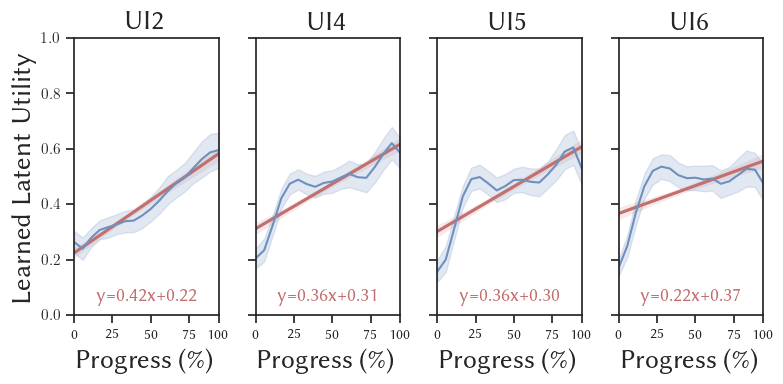

In [77]:
draw_latent_utility_progress('image')